# RLI Galaxy Evolution Code

## Importing and usefull functions

In [26]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as scpo
import scipy.stats
import math
import pandas as pd

class UDS:
    def __init__(self,data_matrix):
        self.data = data_matrix

    @classmethod
    #The bellow function will save the data as a UDS object. The data will be in the form [[row1col1, row1col2,row1col3,...],[row2col1, row2col2, row2col3,...],...]
    def data_excel(cls, file, rows, colums, sheet_nm = "Sheet1"): #"file name",[1,3],"A:B"
        pd_file = pd.read_excel(file + ".xlsx",sheet_name=sheet_nm, usecols= colums)
        just_data = pd_file.iloc[rows[0]-2:rows[1]-1]
        fin_data = just_data.values.tolist()
        return cls(fin_data)
    
#Utility functions
    @staticmethod
    def flatten(matrix):
        flat_list = []
        for row in matrix:
            flat_list.extend(row)
        return flat_list
    @staticmethod
    def sci_e_equal(num1,num2,round = 10):
        e_1 = 10**(int(math.log10(num1))-1)
        if e_1 < 0.0001:
            e_1_s = "{0}".format(e_1)
            e_1_s = e_1_s[1:]
            prop_num2 = "{0}".format((num2 * e_1**-1))
            return prop_num2 + e_1_s
        else:
            e_2 = -1*(int(math.log10(num2))-round) 
            e_2_f = ':.{0}'.format(e_2)
            e_2_f = '{' + e_2_f + 'f}'
            return e_2_f.format(num2)

    def getData(self):  #Return data matrix
        return self.data

#Bellow are methods to calculate and display the error of a value using the functional aproach

    def functional_err(self, f, return_comp = False):
        comp_err = []
        orig_val = []
        for i in self.data:
            orig_val += [i[0]]
        fin_val = f(*orig_val)

        for i in range(len(self.data)):
            cur_val = orig_val.copy()
            cur_val[i] += self.data[i][1]
            comp_err += [abs(f(*cur_val) - fin_val)]

        fin_err = 0
        for i in comp_err:
            fin_err += i**2
        fin_err = (fin_err)**0.5
        
        if return_comp:
            return [[fin_val, fin_err], comp_err]
        return [fin_val, fin_err]
    
    def display_func_err(self, f, show_comp = False, **kwargs):
        fig = plt.figure(1) 
        fig.add_axes((0,0,0.75,0.10))
        ax = fig.gca()

        fx_name = "Z"
        fx_units = "n/a"
        comp_tbl_row = []  #The labels for the component table rows
        alphabet = ["A","B","C","D","E","F","G","H","I","J","K","L","M","N","O","P","Q","R","S","T","U","V","W","X","Y","Z"]

        if 'f_name' in kwargs:
            fx_name = kwargs['f_name']
        if 'f_units' in kwargs:
            fx_units = kwargs['f_units']

        if show_comp:
            all_data = self.functional_err(f,return_comp= True)
            val_fin = all_data[0][0]
            err_fin = all_data[0][1]
            comp_err = all_data[1].copy()
            tbl_comp_err = []  #Holds the actual values to display in the component err table
            var_names = alphabet[:len(self.data)]
            if 'var_names' in kwargs:
                var_names = kwargs['var_names']
            for i in range(len(comp_err)):
                tbl_comp_err += [[comp_err[i]]]
                comp_tbl_row += ["$\\alpha_{0}^{{{1}}}$".format(fx_name,var_names[i])]

        else:
            all_data = self.functional_err(f,return_comp= False)
            val_fin = all_data[0]
            err_fin = all_data[1]


        # hide axes
        ax.axis('off')
        ax.axis('tight')
        axtl = r"{0}\ and\ its\ Error".format(fx_name)
        axtl = "$\\mathbfit{" + axtl + "}$"
        ax.set_title(axtl)
        fx_tbl_contents = [[val_fin,UDS.sci_e_equal(val_fin,err_fin)]]
        fx_tbl_headers = ["${0}$ (${1}$)".format(fx_name,fx_units), "$\\alpha_{0}$ (${1}$)".format(fx_name,fx_units)]

        fx_tbl = ax.table(cellText=fx_tbl_contents,cellLoc="center",colWidths= [0.5,0.5],colLabels=fx_tbl_headers, loc='center') #Table creation
        #setting the height of each cell
        for c in fx_tbl.get_celld().values():
            c.set_height(0.5)


        #### Code for error component tabel
        if show_comp:
            comp_tbl_headers = ["Component of total error (${0}$)".format(fx_units)]
            axis_height = 0.0578*len(comp_err) + 0.1424 #formula to calculate where to begin and the height of the axis based on the amount of component error

            fig.add_axes((0,-1*axis_height,0.75,axis_height))
            ax = fig.gca()
            ax.axis('off')
            ax.axis('tight')


            comp_tbl = ax.table(cellText=tbl_comp_err,cellLoc="center",colWidths=[0.5],colLabels=comp_tbl_headers,rowLabels=comp_tbl_row, loc='center')

            cell_height = 1/(2+len(comp_err))

            for c in comp_tbl.get_celld().values():
                c.set_height(cell_height)
        plt.show()

def remove_points(arr,points):
    n = -1
    for i in points:
        n+= 1
        arr = np.concatenate([arr[:i-n],arr[i+1-n:]])
    return arr
def find_r50(x1,y1,x2,y2):
    return ((0.5-y1)*(x2-x1)/(y2-y1)) + x1

def find_r90(x1,y1,x2,y2):
    return ((0.9-y1)*(x2-x1)/(y2-y1)) + x1
def countToMag(count,zp):
    return -2.5*math.log10(count) + zp

## Reading and basic analysis of data

In [129]:
################ All the files and raw data #######################
all_stats_files = ["B_02_09_stats.txt","B_02_27_stats.txt","B_02_06_stats.txt","V_02_09_stats.txt","V_02_27_stats.txt","V_02_10_stats.txt","r_02_09_stats.txt","r_02_27_stats.txt","r_02_06_stats.txt"]
all_radial_files = ["B_02_09_rad.dat","B_02_27_rad.dat","B_02_06_rad.dat","V_02_09_rad.dat","V_02_27_rad.dat","V_02_10_rad.dat","r_02_09_rad.dat","r_02_27_rad.dat","r_02_06_rad.dat"]
all_labels = ["B draco2 2019/02/09","B draco2 2019/02/27","B east14 2020/02/06","V draco2 2019/02/09","V draco2 2019/02/27","V east14 2019/02/10","r draco2 2019/02/09","r draco2 2019/02/27","r east14 2020/02/06"]
all_mark_styles = ['s','^','o','s','^','o','s','^','o']
all_linestyles = ["--","-.",":","--","-.",":","--","-.",":"]
color_BVr = ['royalblue','royalblue','royalblue','mediumseagreen','mediumseagreen','mediumseagreen','orangered','orangered','orangered']
all_bg = [225,282.4,325.3,840,1186.0,746.3,898.5,1548.5,936.5]
all_bg_err =[0.1,0.1,0.16,0.2,0.3,0.2,0.18,0.3,0.18]
all_zp = [24.598,24.451,24.152,25.442,25.061,25.368,26.211,25.037,24.694]
all_zp_err = [0.011,0.009,0.007,0.008,0.005,0.005,0.037,0.004,0.003]
points_to_remove = [[12,13,19,20,31],[14,21,31,32],[11,16,17,25,36],[12,13,19,20,32,33],[13,20,33,34],[13,14,21,31,32],[13,20,32],[13,20,33],[10,15,16,23,37]]

################ Refining the data a bit ###########################
all_radii = []
all_radii_err = []
all_sb = []
all_sb_err = []
all_br_zoneCount = []
all_br_zoneCount_err = []
all_sum = []
for i in range(9):
    ##### Reading and saving data #####
    reg,flux,flux_err,areas,sb,sb_err  = np.loadtxt(all_stats_files[i],skiprows=7,max_rows=40, unpack=True)
    reg2,sum,npix,mean,meadian,min,max,var,stdev,rms  = np.loadtxt(all_stats_files[i],skiprows=50,max_rows=40, unpack=True)
    rad, sb,sb_err = np.loadtxt(all_radial_files[i], unpack=True)
    all_radii += [rad*3.675*10**6/206265]
    all_radii_err += [rad*0.049*10**6/206265]
    all_sb += [sb]
    all_sb_err += [sb_err]
    all_sum += [sum]

    ###### Corecting for background and getting total counts in each reagion ######
    temp_br_zoneCount = []
    temp_br_zoneCount_err = []
    for j in range(40):
        temp_br_zoneCount += [npix[j]*meadian[j] - areas[j]*all_bg[i]]
        temp_br_zoneCount_err += [( (1.25*(npix[j])**0.5*stdev[j])**2 + (areas[j]*all_bg_err[i])**2 )**0.5]
    all_br_zoneCount += [temp_br_zoneCount]
    all_br_zoneCount_err += [temp_br_zoneCount_err]


## Code for R90/R50

                          R90/R50

B draco2 2019/02/09: 2.3415270373009176 +- 0.07391834562925717
B draco2 2019/02/27: 2.332689493241961 +- 0.05129693014189467
B east14 2020/02/06: 1.8206123436143535 +- 0.03351947032476469

V draco2 2019/02/09: 2.634661118606349 +- 0.059161077236352555
V draco2 2019/02/27: 1.865232761357795 +- 0.03599910796514263
V east14 2019/02/10: 2.5230275586538067 +- 0.06339333647192665

r draco2 2019/02/09: 2.7342595689213542 +- 0.05743197091052735
r draco2 2019/02/27: 2.4615101145656775 +- 0.0499325189998793
r east14 2020/02/06: 2.464323058643395 +- 0.06252804918600254

                          r50

B draco2 2019/02/09: 2332.82115410594 +- 36.35908906326485
B draco2 2019/02/27: 2289.3875217172545 +- 33.11001743109108
B east14 2020/02/06: 3890.859859916477 +- 47.184869563929

V draco2 2019/02/09: 1878.7877753463958 +- 26.094901461250327
V draco2 2019/02/27: 3069.207514042445 +- 39.01089859825191
V east14 2019/02/10: 2033.0459398991443 +- 29.806295921501462

r dr

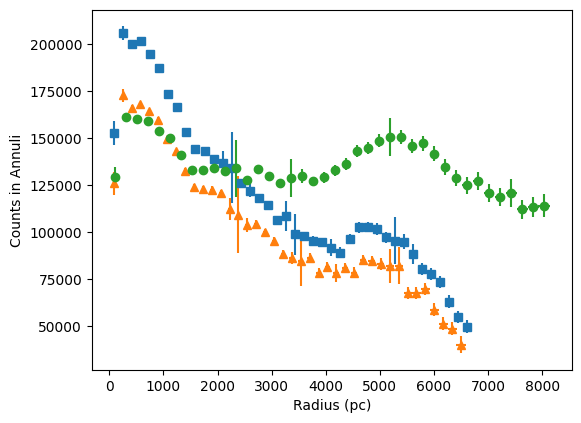

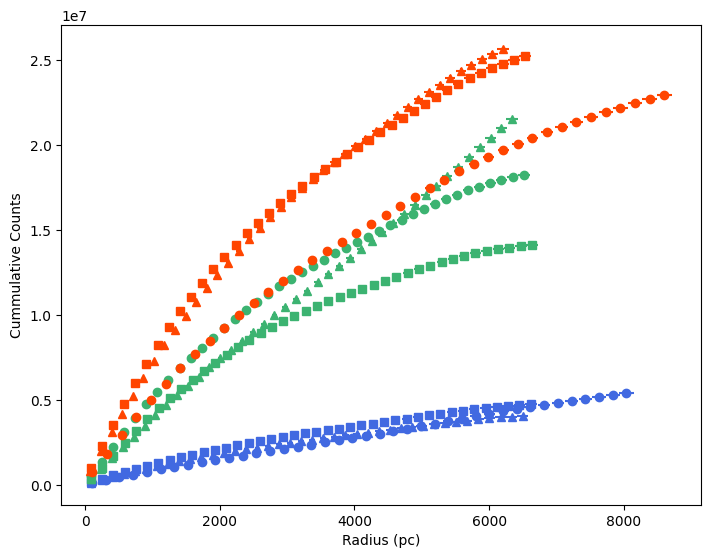

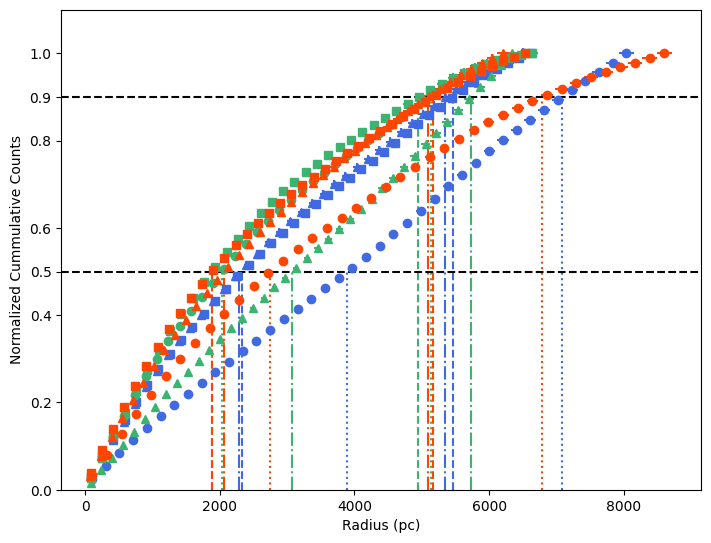

In [143]:
plot_files = (0,1,2,3,4,5,6,7,8)
#########
fig1 = plt.figure(1)
ax1 = fig1.add_axes((0,0,0.75,0.75))
ax1.set_xlabel("Radius (pc)")
ax1.set_ylabel("Counts in Annuli")

fig2 = plt.figure(2)
ax2 = fig2.add_axes((0,0,1,1))
ax2.set_xlabel("Radius (pc)")
ax2.set_ylabel("Cummulative Counts")

fig3 = plt.figure(3)
ax3 = fig3.add_axes((0,0,1,1))
ax3.set_xlabel("Radius (pc)")
ax3.set_ylabel("Normalized Cummulative Counts")
all_r50 = []
all_r90 = []
all_C = []
for i in plot_files:
    if i <3:
        ax1.errorbar(all_radii[i],all_br_zoneCount[i],all_br_zoneCount_err[i],all_radii_err[i],marker=all_mark_styles[i], linestyle='None', label = all_labels[i])

    cum_counts = [all_br_zoneCount[i][0]]
    cum_counts_err = [all_br_zoneCount_err[i][0]]
    norm_cum_counts = []
    norm_cum_counts_err = []
    need_find_r50 = True
    need_find_r90 = True
    for j in range(39):
        cum_counts += [cum_counts[j] + all_br_zoneCount[i][j+1]]
        cum_counts_err += [(cum_counts_err[j]**2 + all_br_zoneCount_err[i][j+1]**2)**0.5]
    for j in range(40):
        norm_cum_counts += [cum_counts[j]/cum_counts[-1]]
        norm_cum_counts_err += [norm_cum_counts[j]*((cum_counts_err[j]/cum_counts[j])**2 + (cum_counts_err[-1]/cum_counts[-1])**2)**0.5]
        if need_find_r50 and norm_cum_counts[j] > 0.5:
            all_r50 += [UDS([[all_radii[i][j-1],all_radii_err[i][j-1]],[norm_cum_counts[j-1],norm_cum_counts_err[j-1]],[all_radii[i][j],all_radii_err[i][j]],[norm_cum_counts[j],norm_cum_counts_err[j]]]).functional_err(find_r50)]
            need_find_r50 = False
        elif need_find_r90 and norm_cum_counts[j] > 0.9:
            all_r90 += [UDS([[all_radii[i][j-1],all_radii_err[i][j-1]],[norm_cum_counts[j-1],norm_cum_counts_err[j-1]],[all_radii[i][j],all_radii_err[i][j]],[norm_cum_counts[j],norm_cum_counts_err[j]]]).functional_err(find_r90)]
            need_find_r90 = False
    all_C += [[all_r90[i][0]/all_r50[i][0], all_r90[i][0]/all_r50[i][0]*((all_r90[i][1]/all_r90[i][0])**2 + (all_r50[i][1]/all_r50[i][0])**2)**0.5]]


    ax2.errorbar(all_radii[i],cum_counts,cum_counts_err,all_radii_err[i],marker=all_mark_styles[i], linestyle='None',color = color_BVr[i], label = all_labels[i])
    ax3.errorbar(all_radii[i],norm_cum_counts,norm_cum_counts_err,all_radii_err[i],marker=all_mark_styles[i], linestyle='None',color = color_BVr[i], label = all_labels[i])
    ax3.axvline(x=all_r50[i][0],ymin=0,ymax=0.4545,linestyle = all_linestyles[i],color=color_BVr[i])
    ax3.axvline(x=all_r90[i][0],ymin=0,ymax=0.8181,linestyle = all_linestyles[i],color=color_BVr[i])
    
ax3.set_yticks(list(ax3.get_yticks()) + [0.5,0.9])
ax3.set_ybound(0,1.1)
ax3.axhline(y=0.5,color = 'black',linestyle = "--")
ax3.axhline(y=0.9,color = 'black',linestyle = "--")

print("                          R90/R50")
print()
for i in plot_files:
    print(all_labels[i] + ": {0} +- {1}".format(all_C[i][0],all_C[i][1]))
    if i == 2 or i == 5:
        print()

print()
print("                          r50")
print()
for i in plot_files:
    print(all_labels[i] + ": {0} +- {1}".format(all_r50[i][0],all_r50[i][1]))
    if i == 2 or i == 5:
        print()

#ax1.legend()
#ax2.legend()
#ax3.legend()
#fig1.savefig("BlueBandRawCData.png",bbox_inches='tight')
#fig3.savefig("CMainPlot.png",bbox_inches='tight')
plt.show()


## Sersic Code

### Point Removing code
The cell below is just so you can visualise the data before fitting it with the chi squared.

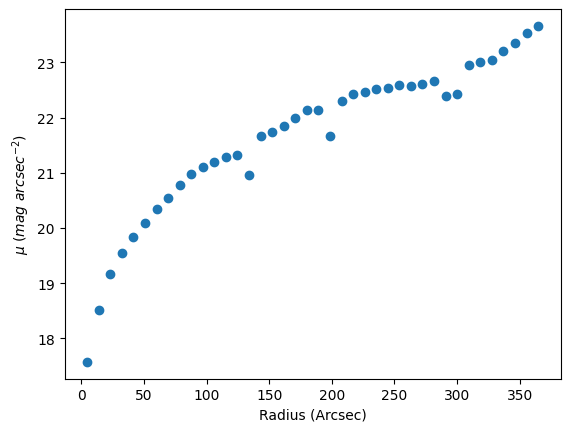

In [ ]:
file_num = 1

file = all_radial_files[file_num]
zp = all_zp[file_num]
zp_err = all_zp_err[file_num]
background = all_bg[file_num]

pix_n, count, count_err  = np.loadtxt(file, unpack=True)
br_count = count - background
br_mag =  []
br_mag_err = []

def countToMag(count,zp):
    return -2.5*math.log10(count) + zp

for i in range(len(count_err)):
    magAndErr = UDS([[br_count[i],count_err[i]],[zp,zp_err]]).functional_err(countToMag)
    br_mag += [magAndErr[0]]
    br_mag_err += [magAndErr[1]]

fig1 = plt.figure(1)
plt.scatter(pix_n,br_mag)
plt.gca().set_xlabel('Radius (Arcsec)')
plt.gca().set_ylabel(r"$\mu$ ($mag\ arcsec^{-2}$)")
#fig1.savefig("RemovalExamplePlotB0227.png",bbox_inches='tight')
plt.show()

### Chi Squared Fitting

B draco2 2019/02/09
reduced chi^2 = 13.680498524154709
optimised parameter[0] = (24.500382468167313 +/- 0.08929713864955319) units
optimised parameter[1] = (11985.982576897502 +/- 604.7277471249445) units
optimised parameter[2] = (5.730494115031619 +/- 0.10513656026659451) units

B draco2 2019/02/27
reduced chi^2 = 9.955422806660845
optimised parameter[0] = (24.162211447891753 +/- 0.07927239624038) units
optimised parameter[1] = (9851.756290181325 +/- 447.32082022283913) units
optimised parameter[2] = (5.281722424388061 +/- 0.08857693272789247) units

B east14 2020/02/06
reduced chi^2 = 14.32274637612419
optimised parameter[0] = (49.70065638040431 +/- 2.906590658591003) units
optimised parameter[1] = (95125801569.77684 +/- 172138549887.30164) units
optimised parameter[2] = (29.506560951814592 +/- 2.840398127475031) units

V draco2 2019/02/09
reduced chi^2 = 123.03154429619971
optimised parameter[0] = (21.127452125062433 +/- 0.014753616432227709) units
optimised parameter[1] = (2420.213

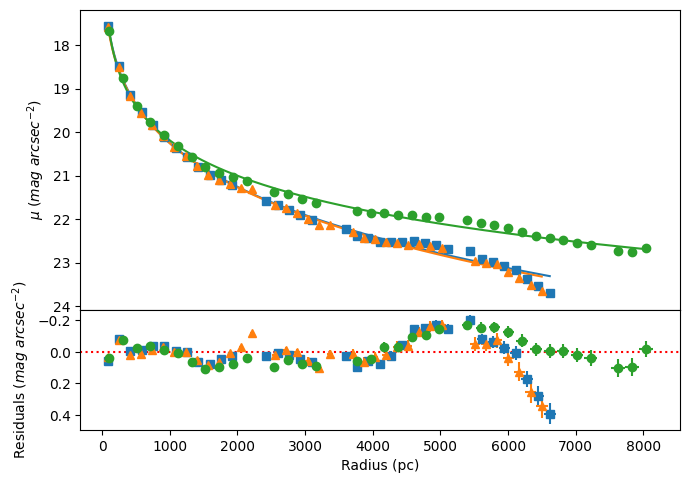

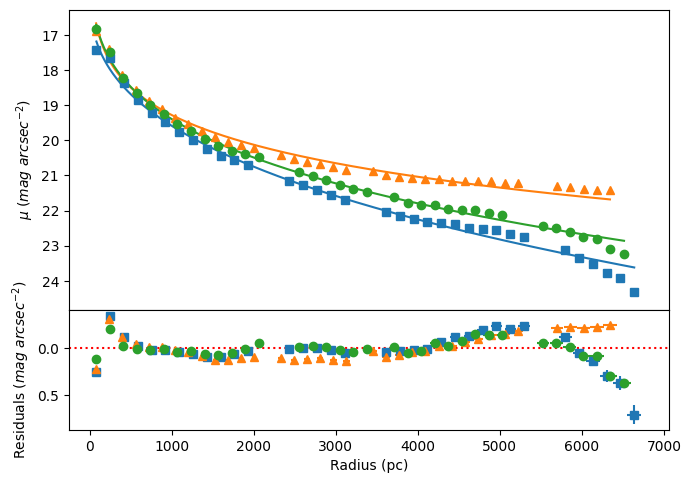

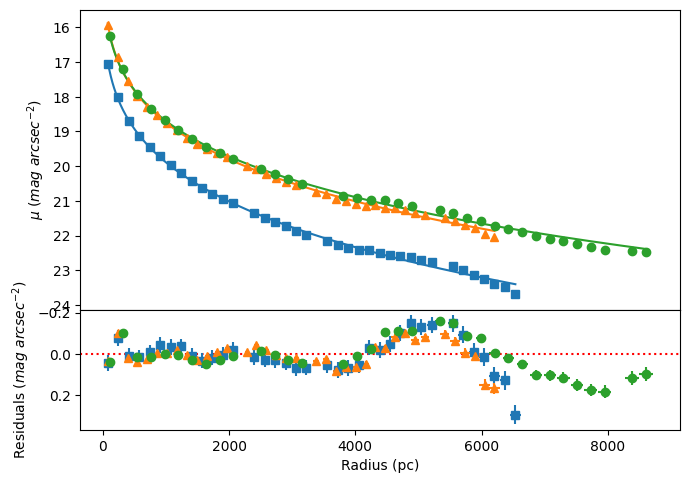

In [ ]:
plot_files = (0,1,2,3,4,5,6,7,8)

fig4 = plt.figure(4,figsize=(6,3))
ax4 = fig4.add_axes((0,0,1,1))
ax4.set_ylabel(r"$\mu$ ($mag\ arcsec^{-2}$)")
ax4_r = fig4.add_axes((0,-0.4,1,0.4),sharex = ax4)
ax4_r.axhline(ls=":",color = 'red')
ax4_r.set_xlabel("Radius (pc)") # Axis labels
ax4_r.set_ylabel(r'Residuals ($mag\ arcsec^{-2}$)')

fig5 = plt.figure(5,figsize=(6,3))
ax5 = fig5.add_axes((0,0,1,1))
ax5.set_ylabel(r"$\mu$ ($mag\ arcsec^{-2}$)")
ax5.xaxis.set_visible(False)
ax5_r = fig5.add_axes((0,-0.4,1,0.4),sharex = ax5)
ax5_r.axhline(ls=":",color = 'red')
ax5_r.set_xlabel("Radius (pc)") # Axis labels
ax5_r.set_ylabel(r'Residuals ($mag\ arcsec^{-2}$)')

fig6 = plt.figure(6,figsize=(6,3))
ax6 = fig6.add_axes((0,0,1,1))
ax6.set_ylabel(r"$\mu$ ($mag\ arcsec^{-2}$)")
ax6_r = fig6.add_axes((0,-0.4,1,0.4),sharex = ax6)
ax6_r.axhline(ls=":",color = 'red')
ax6_r.set_xlabel("Radius (pc)") # Axis labels
ax6_r.set_ylabel(r'Residuals ($mag\ arcsec^{-2}$)')

for i in plot_files:
    rem_rad = remove_points(all_radii[i],points_to_remove[i])
    rem_rad_err = remove_points(all_radii_err[i],points_to_remove[i])
    rem_sb = remove_points(all_sb[i],points_to_remove[i]) - all_bg[i]
    rem_sb_err = ((remove_points(all_sb_err[i],points_to_remove[i]))**2 + (all_bg_err[i])**2 )**0.5
    sb_mag = []
    sb_mag_err = []
    for j in range(len(rem_sb)):
        magAndErr = UDS([[rem_sb[j],rem_sb_err[j]],[all_zp[i],all_zp_err[i]]]).functional_err(countToMag)
        sb_mag += [magAndErr[0]]
        sb_mag_err += [magAndErr[1]]
    


    x_values = rem_rad
    x_errors = rem_rad_err
    y_values = sb_mag
    y_errors = sb_mag_err

    ############################# Function and Initial Values ##############################################

    def model_function(x, *params):
        return params[0] + (2.5*(0.868*params[2]-0.142))*((x/params[1])**(1/params[2]) -1)
    all_init_val = [[4500,20,4.29],[4500,20,4.29],[10000,24,5.29],[4500,20,4.29],[4500,20,4.29],[4500,20,4.29],[4500,20,4.29],[4500,20,4.29],[4500,20,4.29]]
    initial_values = np.array([4500,20,4.29]) # Initial guess for fit parameters

    ########################### Chi Squared Code ############################################################

    popt, cov = scipy.optimize.curve_fit(model_function, # function to fit
                                         x_values, # x data
                                         y_values, # y data
                                         sigma=y_errors, # array of error bars for the fit
                                         absolute_sigma=True, # errors bars DO represent 1 std error
                                         p0=initial_values, # starting point for fit
                                         check_finite=True,
                                         maxfev = 160000,
                                         bounds = ([0,0,0],[np.inf,np.inf,np.inf])) # raise ValueError if NaN encountered (don't allow errors to pass)
    
    ###################### Residual Code ########################
    resid = (sb_mag - model_function(rem_rad,*popt))
    

    if i <= 2:
        p1 = ax4.errorbar(x_values, 
                     y_values, 
                     yerr=y_errors, 
                     marker=all_mark_styles[i], 
                     linestyle='None')
        
        ax4_r.errorbar(rem_rad,resid,sb_mag_err,rem_rad_err, marker = all_mark_styles[i], linestyle='None')

        smooth_x = np.linspace(x_values[0], x_values[-1], 1000) # more points, over range of data
        ax4.plot(smooth_x, 
                 model_function(smooth_x , *popt), color = p1[0].get_color())
        ax4.yaxis.set_inverted(True)
        ax4_r.yaxis.set_inverted(True)
    elif i > 2 and i <= 5:
        p2 = ax5.errorbar(x_values, 
                     y_values, 
                     yerr=y_errors, 
                     marker=all_mark_styles[i-3], 
                     linestyle='None')
        ax5_r.errorbar(rem_rad,resid,sb_mag_err,rem_rad_err, marker = all_mark_styles[i], linestyle='None')

        smooth_x = np.linspace(x_values[0], x_values[-1], 1000) # more points, over range of data
        ax5.plot(smooth_x, 
                 model_function(smooth_x , *popt), color = p2[0].get_color())
        ax5.yaxis.set_inverted(True)
        ax5_r.yaxis.set_inverted(True)
    elif  i > 5:
        p3 = ax6.errorbar(x_values, 
                     y_values, 
                     yerr=y_errors, 
                     marker=all_mark_styles[i-6], 
                     linestyle='None')
        ax6_r.errorbar(rem_rad,resid,sb_mag_err,rem_rad_err, marker = all_mark_styles[i], linestyle='None')
        smooth_x = np.linspace(x_values[0], x_values[-1], 1000) # more points, over range of data
        ax6.plot(smooth_x, 
                 model_function(smooth_x , *popt), color = p3[0].get_color())
        ax6.yaxis.set_inverted(True)
        ax6_r.yaxis.set_inverted(True)


    def chi_squared(model_params, model, x_data, y_data, y_err):
        return np.sum(((y_data - model(x_data, *model_params))/y_err)**2) # Note the `*model_params' here!


    chi_squared_min = chi_squared(popt, model_function, x_values, y_values, y_errors)
    #print('chi^2_min = {}'.format(chi_squared_min))
    print(all_labels[i])
    degrees_of_freedom = x_values.size - popt.size
    print('reduced chi^2 = {}'.format(chi_squared_min/degrees_of_freedom))
    #print('P(chi^2_min, DoF) = {}'.format(scipy.stats.chi2.sf(chi_squared_min, degrees_of_freedom)))

    popt_errs = np.sqrt(np.diag(cov))

    for i, (val, err) in enumerate(zip(popt, popt_errs)):
        print('optimised parameter[{}] = ({} +/- {}) units'.format(i, val, err))

    print()
    ######################################################################################################################

#fig4.savefig("BlueSersicMainPlot.png",bbox_inches='tight')
#fig5.savefig("VisualSersicMainPlot.png",bbox_inches='tight')
#fig4.savefig("RedSersicMainPlot.png",bbox_inches='tight')
plt.show()